# Gemma BFS‑DFS Fork Analysis — a runnable walkthrough of `method.py` (iteration 7)

**What the artifact studies.** `google/gemma-3-4b-it` (bf16) is asked to write `solve(grid, start, goal)`, a path
search on a grid (task **T1**). Every program it writes opens with the same 32 tokens **c\*** (```` ```python ````,
`def solve(grid, start, goal):`, `rows = len(grid)`, `cols = len(grid[0])`, indent). The **next token**, at response
index 32 (the *fork*), decides the algorithm. ` visited` leads to depth-first search (**DFS**). A blank line, `if`,
`queue` or `q` lead to breadth-first search (**BFS**). The *fork margin* is m = logsumexp(z[B]) − z['visited'],
computed from the next-token logits at the fork.

The iteration asks three questions at that fork:
* **G1:** which attention heads and MLPs compute m? (path patching, then ablation and steering in the real model)
* **G2:** does a low-rank DAS subspace act as a *dose dial* that adds **correct** BFS programs?
* **G3:** does the fork margin alone predict what temperature does?

`method.py` is the entry point. It has one function per stage and runs as `python method.py --stage <name>`
(`s0`, `engine`, `label`, `g3a/g3b`, `yv`, `g1p/g1v`, `g2/g2r/g2d`, `novelty`, `analysis`). The stages after
`label` live in `src/g1.py`, `src/g2.py`, `src/g3.py` and `src/analysis7.py`; `method.py` only dispatches to them.

**What runs in this notebook (CPU only; about a minute on 2 cores once the packages are installed).**
1. **Stage S0**'s CPU checks, unrolled from `stage_s0` into one cell per section:
   * the sha256 manifest check;
   * the frozen labeller on the T1 reference programs;
   * the hidden-test checker against 5 broken programs;
   * the common-random-number (CRN) streams;
   * the **DAS toy** with a planted rank-2 subspace;
   * the instrument revisions;
   * the hash-chained **commit #0**.
2. **Stage label** (`stage_label`, which runs the frozen labeller). It labels Gemma's G3-cal programs from scratch
   (prompt + c\* + one *forced* fork token) and compares the labels with the recorded ones.

**What is only shown.** The GPU stages need Gemma-3-4B on a CUDA GPU (about 2.4 GPU-hours in the original run).
`stage_engine` and the GPU section of S0 are kept verbatim as function definitions but are not called. Their recorded
outputs are loaded from `mini_demo_data.json` and plotted at the end: the fork calibration, the G2 dose dial, the
G3 temperature law and the fork-margin geometry.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install (method.py, src/cfg.py and the vendored labeller log with it)
_pip('loguru==0.7.3')

# numpy, pandas, matplotlib, huggingface_hub, torch -- pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0', 'huggingface_hub==1.4.0')
    _pip('torch==2.9.0+cpu', '--extra-index-url', 'https://download.pytorch.org/whl/cpu')

## Imports

This is the import block of `method.py`, copied as-is. The one exception is its `from cfg import ...` line, which
runs a few cells later: `src/cfg.py` travels inside `mini_demo_data.json` and must be written to disk first. The
notebook also imports numpy and torch, which `method.py` imports inside its stage functions, and pandas and
matplotlib for the results.

In [2]:
"""Iteration 7: circuit and dose dial at Gemma's BFS-vs-DFS fork (google/gemma-3-4b-it, bf16).

Entry point; one function per stage, run as `.venv/bin/python method.py --stage <name>`:
  s0       CPU tests (labeller on references, checker mutants, token ids, c*, CRN, DAS toy), instrument ids,
           GPU batch-shape time test, COMMIT #0
  engine   GPU unit tests U1-U4, engine check (twin N=50 vs iteration 6), U6 (a) multi-prompt vs (b) single-prompt
           re-run, G3-cal (P(BFS | fork token) with the main engine)
  label    CPU label worker over data/raw_*.jsonl (frozen exp8 T1 labeller; follow mode with --follow)
  g3a      G3 predictions from teacher-forced logits (COMMIT #1)          -> src/g3.py
  g3b      G3 temperature sweep (T x sampler, N=50 per cell)                -> src/g3.py
  yv       y_v for the 120 twin variants + fork states (layers 17-29) for bases and 40 forced sources -> src/g2.py
  g1p      G1 path patching on heads/MLPs (AtP screen, exact patching, edges)  -> src/g1.py
  g1v      G1 validation in the real model (teacher-forced, random matched nulls, COMMIT #2, generation) -> src/g1.py
  g2       G2 DAS (layer scan, nested ranks, seeds) + RAND/SHUF/DiM/natural-variance controls -> src/g2.py
  g2r      G2 RINIT control on a randomly initialised Gemma                 -> src/g2.py
  g2d      G2 dose sweep in generation (COMMIT #3 first) + G2-L             -> src/g2.py
  novelty  novelty audit of every correct 'other' program + style re-gate (OpenRouter)
  analysis / figures / outputs
"""

from __future__ import annotations

import argparse
import json
import sys
import time
from pathlib import Path
from typing import Any

from loguru import logger  # noqa: E402

# notebook additions
import importlib.util
import shutil
import types

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

## Load the demo data

`mini_demo_data.json` (about 550 kB) holds:
* **`examples`**: 100 of the 500 G3-cal rows (`g3_calibration_fork_token` in `full_method_out.json`). Each row is
  a program Gemma wrote after the prompt, c\* and one forced fork token (` visited`, blank line, `if`, `queue`), with
  its recorded label. The rows are slots 0–4 of every (token × template) cell, so every block of 4 rows covers all
  four tokens.
* **`files`**: byte-exact copies of the files that `method.py`'s CPU stages read:
  * the T1 part of the frozen *exp8* labeller suite (vendored read-only from iteration 6);
  * `src/cfg.py`, `src/label_worker.py`, `src/regate_rules.py` and `src/commit.py`.
* **`manifest_lines`** and **`fork`**: iteration 6's sha256 lines for those files, and c\*.
* **`recorded`**: the outputs of the GPU stages from the original run.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-7/experiment-38/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["method_name"], "|", data["metadata"]["model"])
print(f"{len(data['examples'])} examples ({data['metadata']['dataset']}), {len(data['files'])} files, "
      f"recorded results: {', '.join(sorted(data['recorded']))}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Circuit and dose dial at Gemma's BFS-vs-DFS fork (iteration 7) | google/gemma-3-4b-it@093f9f388b31de276ce2de164bdc2081324b9767 (bf16)
100 examples (g3_calibration_fork_token), 31 files, recorded results: costs, das_toy, deviations, engine_check, g1_extras, g1_generation, g1_pathpatch, g1_validation, g2_decisions, g2_dose, g2_layer_scan, g2_rinit, g3_cal, g3_predictions, g3_sweep, novelty_audit, regate, s0_tests, tests_gpu_s1, timing, u6, verify_chain, yv


## Recreate the artifact's folder layout

`method.py` resolves every path from its own folder (`ROOT`):
* `src/` holds its modules;
* `inputs/iter6_gemma/` is the read-only copy of iteration 6, where the frozen labeller suite lives;
* `data/`, `results/` and `predictions/` receive the outputs.

This cell writes the shipped files under `ROOT = ./demo_artifact`. It wipes that folder first (only if it holds a
previous run of this notebook) so a re-run starts clean, because commitments are write-once and the label worker
skips rows it has already labelled. Then comes the rest of
`method.py`'s import block, including the `from cfg import ...` line.

In [5]:
# Original: ROOT = Path(__file__).resolve().parent  (the artifact folder; a notebook has no __file__)
ROOT = Path.cwd() / "demo_artifact"
if (ROOT / "src" / "cfg.py").exists():          # a previous run of this notebook: start clean
    shutil.rmtree(ROOT)
for rel, text in data["files"].items():
    p = ROOT / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_bytes(text.encode("utf-8"))          # byte-exact, so S0's sha256 manifest check is meaningful
(ROOT / "inputs" / "iter6_gemma" / "MANIFEST.sha256").write_text("\n".join(data["manifest_lines"]) + "\n")
print(f"wrote {len(data['files'])} files under ./{ROOT.name}/:")
for d in sorted({str(Path(r).parent) for r in data["files"]}):
    print("   ", d)

wrote 31 files under ./demo_artifact/:
    inputs/iter6_gemma/inputs/exp8/suite
    inputs/iter6_gemma/inputs/exp8/suite/labeller
    inputs/iter6_gemma/inputs/exp8/suite/tasks
    inputs/iter6_gemma/inputs/exp8/suite/tasks/t1_grid
    inputs/iter6_gemma/inputs/exp8/suite/tasks/t1_grid/references
    src


In [6]:
sys.path.insert(0, str(ROOT / "src"))

from cfg import (B_IDS, CT_COMMIT, D_IDS, DATA_DIR, DISPLAY_PAIRS, FORCED_TEMPLATES, I6, I6_DATA, I6_NATURAL,  # noqa: E402
                 I6_RESULTS, IT_ID, IT_REV, MAX_NEW, PRED_DIR, RESULTS_DIR, SCOPE_REPO, TC_REPO, TC_REV, TC_SUB,
                 TEMPLATE_IDS, add_deviation, append_jsonl, container_ram_gb, detect_cpus, read_json, read_jsonl,
                 set_ram_limit, setup_logging, sha256_file, slot_key7, slot_key_i6, utc_now, write_json)

# notebook addition: readable names for the fork tokens
FORK_TOKEN_NAME = {int(k): v for k, v in data["metadata"]["fork_tokens"].items()}
print("model:", IT_ID, "@", IT_REV[:12], "| MAX_NEW =", MAX_NEW)
print("B (BFS-leaning fork tokens):", list(B_IDS), " D (DFS):", list(D_IDS), " names:", FORK_TOKEN_NAME)
print("twin templates:", TEMPLATE_IDS, "| forced templates:", list(FORCED_TEMPLATES), "| display pairs:", DISPLAY_PAIRS[:2])

model: google/gemma-3-4b-it @ 093f9f388b31 | MAX_NEW = 1024
B (BFS-leaning fork tokens): [107, 584, 15204, 236809]  D (DFS): [53227]  names: {53227: 'visited', 107: '\\n', 584: 'if', 15204: 'queue'}
twin templates: ['W1', 'W2', 'W3', 'W4', 'W5'] | forced templates: ['F1', 'F2', 'F3', 'F4', 'F5'] | display pairs: (('BFS', 'DFS'), ('breadth-first search', 'depth-first search'))


## Config

All tunable sizes are in one place. The values below are the ones this notebook was tested with: everything except
the number of re-labelled programs equals the original, and the whole notebook runs in about a minute on 2 CPU cores.
* `N_REFERENCES`: reference programs labelled in S0 (original: all 12).
* `N_PROGRAMS`: Gemma programs re-labelled by the label stage. The mini data holds 100; the original labelled all
  500 G3-cal rows (4 tokens × 5 templates × 25 slots).
* `CRN_N`: length of the CRN streams compared in S0.
* `TOY_D`, `TOY_RUNS`: the size and optimiser settings of the DAS toy. With the original values it takes about
  30 s on CPU.
* `LIST_INSTRUMENTS`: query the Hugging Face Hub for the transcoder and Gemma Scope 2 revisions. This needs internet;
  with `False` the recorded revisions are used.

In [7]:
N_REFERENCES = 12     # T1 reference programs labelled in S0 (original: all 12 in tasks/t1_grid/references)
N_PROGRAMS = 100      # Gemma G3-cal programs re-labelled by the label stage (mini data: 100;
                      #   original: 500 = 4 forced fork tokens x 5 templates x 25 slots)
CRN_N = 2048          # length of the two CRN uniform streams compared in S0 (original: 2048)
TOY_D = 2560          # DAS-toy dimension (original: D_MODEL = 2560, Gemma-3-4B's residual width)
TOY_RUNS = {          # DAS-toy runs: (n_train pairs, Adam lr, steps, batch) -- the original values
    "das": (4096, 2e-2, 800, 512),                  # also used by SHUF (shuffled targets)
    "plan_optimiser_lr2e-3": (4096, 2e-3, 400, 64),
    "small_n_overfit": (256, 2e-2, 300, 256),
}
LIST_INSTRUMENTS = True   # query the Hugging Face Hub for instrument revisions (original: always; False = recorded)

## Pre-registration constants

`method.py` keeps the decision rules, the order in which parts would be dropped under time pressure, and the parts
that are never dropped. `stage_s0` hashes all three into **commit #0** before any decisive sample is drawn. Later
commits chain onto it: #1 the G3 predictions, #2/#2b the G1 node selection, #3 the dose plan. `GPU_STAGES` lists
the stages that skip the RAM limit, because CUDA reserves a huge virtual address space.

In [8]:
GPU_STAGES = ("s0", "engine", "g3a", "g3b", "yv", "g1p", "g1v", "g2", "g2r", "g2d", "g2smoke", "g1gen", "g2pairs")

DECISION_RULES = {
    "ENGINE_CHECK": "Pass if the twin BFS share (N=50, natural sampling T=1 top-p 1) lies inside iteration 6's Wilson "
                    "95% CI [0.245, 0.372] for 61/200; per-slot label agreement with iteration 6's rows is reported "
                    "whatever it is.",
    "U6": "200 continuations from the empty response prefix: (a) fork-resampling path (multi-prompt batches, partial "
          "labeller; also labelled with the full labeller) and (b) the main single-prompt fixed-shape engine; each is "
          "compared with the natural share (two-proportion exact test). Diagnosis: labeller (a-partial vs a-full), "
          "batching ((a) vs (b)), or neither.",
    "G3_SOURCE_RULE": "PRIMARY P(BFS | t) for t in B and D is iteration 6's token table UNLESS the U6 diagnosis shows "
                      "that path (a) differs from (b) at p < 0.05; then the primary is the G3-cal estimate. The other "
                      "source is reported as the sensitivity.",
    "NODE_CLAIM": "Holm p < 0.05 (exact one-sided sign-flip permutation over the 20 variant prompts, Holm over the "
                  "top 10) AND the median d_i is in the expected direction AND joint top-5 beats >= 95% of its random "
                  "sets on the median over prompts.",
    "G2_DAS_REAL": "At some k <= 8 (seed median), DAS recovery - RAND recovery >= 0.4 (paired Wilcoxon over held-out "
                   "pairs, p < 0.01) AND SHUF held-out recovery <= 0.1 AND RINIT held-out effect < 0.5 x the trained "
                   "model's effect in nats.",
    "SMALLEST_SUFFICIENT_RANK": "the smallest k with recovery >= 0.8.",
    "ONE_DIMENSIONAL_WORDING": "only if k=1 recovery >= 0.8 AND Spearman(R_1^T h_v, y_v) >= 0.5 (p < 0.01) AND "
                               "G2-KNOB holds; otherwise 'a rank-k subspace carries the forced-prompt transfer'.",
    "DORMANT_FLAG": "share_k at or below the 95th percentile of random AND |Spearman| < 0.2.",
    "K_STAR": "the smallest k whose train-CV recovery >= 0.9 x the maximum over k.",
    "G2_KNOB": "some BFS-direction dose has correct-BFS > the twin's (exact one-sided McNemar on CRN pairs, Holm over "
               "the 6 doses of that method, p < 0.05) AND pass >= 0.8 x the twin's pass; evaluated for DAS and DiM "
               "separately.",
    "G3_CONC": "pooled H(label | fork class) <= 0.3 bits.",
    "G3_LAW": "|pred - obs| <= 0.10 in every top-p-1 cell (top-k cells reported separately).",
    "G3_DISCONFIRMED": "H > 0.5 bits or any top-p-1 cell misses by more than 0.2.",
    "G3_MAE": "MAE <= 0.10 per cell.",
}
DROP_ORDER = ["G1 generation beyond 5 nodes (top-10 and DFS arms)", "the random-init control at the second layer",
              "G3 top-k at T0.7", "G2-N", "G2-L", "G3 top-k T1.3",
              "the DFS-direction DiM cells (keep DAS toward DFS at 0.2 / 0.5 / 1)"]
NEVER_DROP = ["G1 (graph or G1-P) validated in the real model on the teacher-forced margin",
              "G2 with RAND, SHUF, RINIT at L*, held-out templates, the natural-variance check and the BFS-direction "
              "dose sweep for DAS and DiM", "G3 at top-p 1 with its committed predictions", "the novelty audit",
              "the engine check and U6"]

# notebook addition: show the rules as a table
pd.set_option("display.max_colwidth", None)
display(pd.DataFrame({"rule": list(DECISION_RULES.values())}, index=list(DECISION_RULES)))

,rule
ENGINE_CHECK,"Pass if the twin BFS share (N=50, natural sampling T=1 top-p 1) lies inside iteration 6's Wilson 95% CI [0.245, 0.372] for 61/200; per-slot label agreement with iteration 6's rows is reported whatever it is."
U6,"200 continuations from the empty response prefix: (a) fork-resampling path (multi-prompt batches, partial labeller; also labelled with the full labeller) and (b) the main single-prompt fixed-shape engine; each is compared with the natural share (two-proportion exact test). Diagnosis: labeller (a-partial vs a-full), batching ((a) vs (b)), or neither."
G3_SOURCE_RULE,PRIMARY P(BFS | t) for t in B and D is iteration 6's token table UNLESS the U6 diagnosis shows that path (a) differs from (b) at p < 0.05; then the primary is the G3-cal estimate. The other source is reported as the sensitivity.
NODE_CLAIM,"Holm p < 0.05 (exact one-sided sign-flip permutation over the 20 variant prompts, Holm over the top 10) AND the median d_i is in the expected direction AND joint top-5 beats >= 95% of its random sets on the median over prompts."
G2_DAS_REAL,"At some k <= 8 (seed median), DAS recovery - RAND recovery >= 0.4 (paired Wilcoxon over held-out pairs, p < 0.01) AND SHUF held-out recovery <= 0.1 AND RINIT held-out effect < 0.5 x the trained model's effect in nats."
SMALLEST_SUFFICIENT_RANK,the smallest k with recovery >= 0.8.
ONE_DIMENSIONAL_WORDING,"only if k=1 recovery >= 0.8 AND Spearman(R_1^T h_v, y_v) >= 0.5 (p < 0.01) AND G2-KNOB holds; otherwise 'a rank-k subspace carries the forced-prompt transfer'."
DORMANT_FLAG,share_k at or below the 95th percentile of random AND |Spearman| < 0.2.
K_STAR,the smallest k whose train-CV recovery >= 0.9 x the maximum over k.
G2_KNOB,"some BFS-direction dose has correct-BFS > the twin's (exact one-sided McNemar on CRN pairs, Holm over the 6 doses of that method, p < 0.05) AND pass >= 0.8 x the twin's pass; evaluated for DAS and DiM separately."


## Stage S0: CPU tests and commit #0

In the original, `stage_s0(args)` is a single function. Here its body is unrolled into one cell per section, in the
original order. Each section adds its result to the dict `res`, which is written to `results/s0_tests.json` before
commit #0. Two sections need the Gemma tokenizer or a GPU (the token ids and the batch-shape time test). They stay
verbatim inside functions that are defined but not called, and their recorded values are filled in.

### S0 · inputs manifest

Iteration 6's files were vendored read-only, together with a `MANIFEST.sha256`. S0 re-hashes every listed file.
This notebook checks the files it ships (the labeller suite); the original checked all 133 vendored files.

In [9]:
# ================================================================================================ S0
# main() parses `--stage s0` from the command line; the notebook builds the same namespace instead
args = argparse.Namespace(stage="s0", follow=False, n_cal=25, quick=False, part="all")
setup_logging(f"stage_{args.stage}")
logger.info(f"stage {args.stage} start")

# stage_s0 imports numpy, engine (EG), fork7 (FK), prompts (PG) and cfg's SUITE/bench_paths. engine, fork7 and prompts
# need torch+CUDA or the Gemma tokenizer; the two functions the CPU sections use are copied further down.
from cfg import SUITE, bench_paths

t0 = time.time()
res: dict[str, Any] = {}
# ---------------- inputs: the vendored iteration-6 files match their manifest
man = (I6 / "MANIFEST.sha256").read_text().splitlines()
bad = []
for ln in man:
    h, p = ln.split(None, 1)
    if sha256_file(I6 / p.strip().lstrip("./")) != h:
        bad.append(p)
res["inputs_manifest"] = {"n_files": len(man), "n_mismatch": len(bad), "branch": "A (iteration-6 files readable)"}
print("this notebook:", res["inputs_manifest"])
print("original run: ", data["recorded"]["s0_tests"]["inputs_manifest"])

10:19:46|INFO   |stage s0 start


this notebook: {'n_files': 27, 'n_mismatch': 0, 'branch': 'A (iteration-6 files readable)'}
original run:  {'n_files': 133, 'n_mismatch': 0, 'branch': 'A (iteration-6 files readable)'}


### S0 · the frozen labeller on the reference programs, and the checker against mutants

The **labeller** decides which algorithm a program implements. It never asks an LLM unless its two mechanical views
disagree:
* **Hidden tests.** `tasks/harness.py` runs the program in a fresh, stdlib-only `python -I -S` subprocess on the 48
  hidden grids in `tasks/t1_grid/tests.json` and checks every returned path.
* **Runtime label.** `labeller/tracer.py` re-runs the program on probe grids with instrumentation installed: deque,
  heap and queue operations, FIFO versus LIFO `list.pop`, recursion depth and grid access order.
  `labeller/runtime_rules.py` turns those traces into a label.
* **AST label.** `labeller/ast_rules.py` reads the same program's syntax tree for structural cues (a stack, a queue,
  a heap with a Manhattan heuristic, iterative deepening, two frontiers).

If the runtime and AST labels agree, that is the label. Otherwise a blind LLM judge decides. The 12 T1 references
cover the six modes `bfs`, `dfs`, `bibfs`, `iddfs`, `astar_gbfs` and `dijkstra`. `_mutants` builds five broken
versions of the BFS reference, and the hidden tests must reject all five.

In [10]:
def _mutants(ref: str) -> dict[str, str]:
    """Five hand-made wrong programs derived from the BFS reference (each must FAIL the hidden tests)."""
    m = {}
    m["wrong_path_gap"] = ref.replace("return path[::-1]", "p = path[::-1]\n    return p[:1] + p[2:] if len(p) > 2 else p")
    m["through_obstacle"] = ref.replace("and grid[nr][nc] == '.' ", "").replace(
        "if grid[sr][sc] == '#' or grid[gr][gc] == '#':\n        return []", "pass")
    m["diagonal_moves"] = ref.replace("((-1, 0), (1, 0), (0, -1), (0, 1))",
                                      "((-1, 0), (1, 0), (0, -1), (0, 1), (1, 1), (-1, -1), (1, -1), (-1, 1))")
    m["wrong_endpoint"] = ref.replace("return path[::-1]", "return path[::-1][:-1] if len(path) > 1 else path")
    m["missing_unreachable"] = ref.replace("if goal not in parent:\n        return []",
                                           "if goal not in parent:\n        return [start, goal]")
    for k, v in m.items():
        assert v != ref, k
    return m


t_lab = time.time()
# ---------------- labeller on every reference + checker mutants
bench_paths()
import label_worker as LW

refs = sorted((SUITE / "tasks" / "t1_grid" / "references").glob("*.py"))[:N_REFERENCES]   # demo: N_REFERENCES of 12
mode_of = {"astar": "astar_gbfs", "gbfs": "astar_gbfs", "bfs": "bfs", "bibfs": "bibfs", "dfs": "dfs",
           "dijkstra": "dijkstra", "iddfs": "iddfs"}
ref_rows = []
for f in refs:
    want = mode_of[f.stem.split("_")[0]]
    mech = LW._path_mech("t1", f.read_text())
    ref_rows.append({"file": f.name, "want": want, "runtime": mech["runtime_label"], "ast": mech["ast_label"],
                     "passed": mech["passed"],
                     "ok": mech["runtime_label"] == want and mech["ast_label"] == want and mech["passed"]})
res["labeller_references"] = {"n": len(ref_rows), "n_ok": sum(r["ok"] for r in ref_rows),
                              "modes_covered": sorted({r["want"] for r in ref_rows}), "rows": ref_rows}
from tasks.harness import run_tests

ref_bfs = (SUITE / "tasks" / "t1_grid" / "references" / "bfs_deque_parent.py").read_text()
mut = {}
for k, code in _mutants(ref_bfs).items():
    t = run_tests("t1", code)
    mut[k] = {"passed": bool(t.get("passed")), "n_passed": t.get("n_passed")}
res["checker_mutants"] = {"n": len(mut), "n_rejected": sum(not v["passed"] for v in mut.values()), "rows": mut}

print(f"labeller on references: {res['labeller_references']['n_ok']}/{res['labeller_references']['n']} ok, "
      f"mutants rejected: {res['checker_mutants']['n_rejected']}/{res['checker_mutants']['n']} "
      f"({time.time() - t_lab:.0f}s)")
display(pd.DataFrame(ref_rows))
display(pd.DataFrame(mut).T.rename_axis("mutant (of bfs_deque_parent.py)"))

labeller on references: 12/12 ok, mutants rejected: 5/5 (5s)


,file,want,runtime,ast,passed,ok
0,astar_fg.py,astar_gbfs,astar_gbfs,astar_gbfs,True,True
1,bfs_deque_parent.py,bfs,bfs,bfs,True,True
2,bfs_listpop_pathcarry.py,bfs,bfs,bfs,True,True
3,bibfs_deques.py,bibfs,bibfs,bibfs,True,True
4,bibfs_sets.py,bibfs,bibfs,bibfs,True,True
5,dfs_recursive.py,dfs,dfs,dfs,True,True
6,dfs_stack.py,dfs,dfs,dfs,True,True
7,dijkstra_counter.py,dijkstra,dijkstra,dijkstra,True,True
8,dijkstra_lazy.py,dijkstra,dijkstra,dijkstra,True,True
9,gbfs_counter.py,astar_gbfs,astar_gbfs,astar_gbfs,True,True


,passed,n_passed
mutant (of bfs_deque_parent.py),,
wrong_path_gap,False,2
through_obstacle,False,1
diagonal_moves,False,2
wrong_endpoint,False,2
missing_unreachable,False,4


### S0 · token ids, c\* and prompt alignment (needs the gated Gemma tokenizer, not run here)

This section checks four things:
* the fork classes' token ids decode to `\n`, `if`, `queue`, `q` (B) and `visited` (D);
* c\* decodes to the canonical opening;
* each BFS/DFS display-name pair has equal token counts;
* forced and variant prompts are length-aligned, so interchange interventions line up position by position.

It needs the gated `google/gemma-3-4b-it` tokenizer and `src/prompts.py`/`src/fork7.py`, so it is kept as a
function and its recorded result is used. Below it, c\* from iteration 6's fork table.

In [11]:
def s0_token_ids_and_alignment(res: dict[str, Any]) -> None:
    """stage_s0's token-id section, verbatim. Not called in this notebook: PG.tokenizer() loads the gated
    google/gemma-3-4b-it tokenizer; FK/PG are src/fork7.py and src/prompts.py (prompt builders, iteration 6's c*)."""
    import fork7 as FK
    import prompts as PG

    # ---------------- token ids, c*, prompt alignment
    tok = PG.tokenizer()
    dec_B = [tok.decode([t]) for t in B_IDS]
    dec_D = [tok.decode([t]) for t in D_IDS]
    cs = FK.cstar()
    res["token_ids"] = {"B": dict(zip(map(str, B_IDS), dec_B)), "D": dict(zip(map(str, D_IDS), dec_D)),
                        "B_ok": [d.strip() if d.strip() else d for d in dec_B] == ["\n", "if", "queue", "q"],
                        "D_ok": dec_D[0].strip() == "visited",
                        "cstar_text_ok": tok.decode(cs) == FK.fork_table()["cstar_text"], "cstar_len": len(cs)}
    pair_tok = {f"{a} / {b}": [len(tok(" " + a, add_special_tokens=False)["input_ids"]),
                               len(tok(" " + b, add_special_tokens=False)["input_ids"])] for a, b in DISPLAY_PAIRS}
    lens = {}
    for f in FORCED_TEMPLATES:
        for pi in range(len(DISPLAY_PAIRS)):
            pb, pd = FK.forced("bfs", f, pi), FK.forced("dfs", f, pi)
            lens[f"{f}|{pi}"] = [pb["P"], pd["P"]]
            assert pb["P"] == pd["P"], f"forced pair {f}/{pi} lengths differ"
    V = FK.variants()
    by_w: dict[str, set[int]] = {}
    for v in V:
        by_w.setdefault(v["template"], set()).add(v["P"])
    assert all(len(s) == 1 for s in by_w.values()), "variants of one template differ in length"
    res["prompt_alignment"] = {"display_pair_token_counts": pair_tok, "forced_pair_lengths": lens,
                               "variant_lengths_by_template": {w: sorted(s) for w, s in by_w.items()},
                               "n_variants": len(V), "twin_lengths": {w: FK.twin(w)["P"] for w in TEMPLATE_IDS}}


res["token_ids"] = data["recorded"]["s0_tests"]["token_ids"]                 # recorded (original run)
res["prompt_alignment"] = data["recorded"]["s0_tests"]["prompt_alignment"]
print("token ids:", json.dumps(res["token_ids"]))
print("display-name token counts:", res["prompt_alignment"]["display_pair_token_counts"])
print("twin prompt lengths:", res["prompt_alignment"]["twin_lengths"], "| variants:", res["prompt_alignment"]["n_variants"])
print(f"\nc* = response tokens 0-{data['fork']['fork_token_index'] - 1}; the fork token follows at index "
      f"{data['fork']['fork_token_index']}:\n")
print(data["fork"]["cstar_text"] + "<FORK TOKEN: ' visited' -> DFS | blank line, 'if', 'queue', 'q' -> BFS>")

token ids: {"B": {"107": "\n", "584": "if", "15204": "queue", "236809": "q"}, "D": {"53227": "visited"}, "B_ok": true, "D_ok": true, "cstar_text_ok": true, "cstar_len": 32}
display-name token counts: {'BFS / DFS': [1, 1], 'breadth-first search / depth-first search': [4, 4], 'a breadth-first search / a depth-first search': [5, 5], 'breadth-first search (BFS) / depth-first search (DFS)': [7, 7]}
twin prompt lengths: {'W1': 248, 'W2': 247, 'W3': 244, 'W4': 246, 'W5': 249} | variants: 120

c* = response tokens 0-31; the fork token follows at index 32:

```python
def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0])
    <FORK TOKEN: ' visited' -> DFS | blank line, 'if', 'queue', 'q' -> BFS>


### S0 · common random numbers (CRN)

Every sample is drawn by inverse-CDF sampling from **one uniform stream per slot**. The stream is seeded with PCG64
from the sha256 of the slot key, for example `('iter7GU6', 'T1', 'W1', 0)`. Two arms that share a slot therefore
see the same random numbers and differ only through the intervention, which makes paired exact tests (McNemar)
possible. S0 checks that a stream is bit-identical across two calls. `u_stream` comes from `src/engine.py`, whose
other functions need CUDA, so it is copied here.

In [12]:
from cfg import stable_seed


def u_stream(*key: Any, n: int) -> np.ndarray:            # copied from src/engine.py (section 'sampling')
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


EG = types.SimpleNamespace(u_stream=u_stream)             # so that the original `EG.u_stream(...)` lines run unchanged

# ---------------- CRN streams bit-identical across two calls
a = EG.u_stream("iter7GU6", "T1", "W1", 0, n=CRN_N)
b = EG.u_stream("iter7GU6", "T1", "W1", 0, n=CRN_N)
res["crn_identical"] = bool(np.array_equal(a, b))
print("crn_identical:", res["crn_identical"])
print("slot (iter7GU6, T1, W1, 0):", np.round(a[:5], 4), "| slot k = 1:",
      np.round(EG.u_stream("iter7GU6", "T1", "W1", 1, n=5), 4))

crn_identical: True
slot (iter7GU6, T1, W1, 0): [0.5043 0.9273 0.691  0.7169 0.4463] | slot k = 1: [0.1711 0.9957 0.3104 0.0377 0.021 ]


### S0 · DAS toy: does the training loop find a planted subspace?

**Distributed alignment search (DAS)** learns an orthonormal basis R (D × k). Patching a *source* state's projection
onto R into a *base* state, x' = x + ((x_s − x) R) Rᵀ, should reproduce the source's output distribution; the loss
is KL(source ‖ patched). In G2 the base and source are Gemma's residual states at the fork. Here the toy draws a
D-dimensional Gaussian whose 3-class readout depends only on a planted rank-2 subspace Q. DAS (rank 2) must recover
Q, meaning principal-angle cosines between R and Q above 0.9. The controls:
* **SHUF** (shuffled training targets) must fail on held-out pairs;
* **RAND** (a random R) must have cosines near 0;
* the **plan's optimiser** (Adam lr 2e‑3, 400 steps, batch 64) barely moves the subspace, which is why the run used
  lr 2e‑2 (deviation D04);
* **small n** (256 pairs for 5,120 parameters) overfits, which is why held-out pairs are decisive.

`toy_test` is copied from `src/g2.py`. The only changes: its dimension and run settings come from the config cell.

In [13]:
D_MODEL = TOY_D   # src/cfg.py: D_MODEL = 2560 (Gemma-3-4B residual width); the toy's dimension comes from the config


def toy_test(seed: int = 0) -> dict[str, Any]:
    """Synthetic check of the DAS loop: a 2560-d Gaussian with a planted rank-2 causal subspace Q driving a 3-class
    readout. DAS (rank 2) must recover Q (principal-angle cosines > 0.9); RAND must not; SHUF must fail held-out.
    Also reported: the plan's optimiser setting (Adam lr 2e-3, 400 steps, batch 64) and a small-n run (256 pairs <
    5,120 parameters), which overfits (train KL -> 0, held-out KL high) -- the reason held-out pairs are decisive."""
    D = D_MODEL
    g = torch.Generator().manual_seed(seed)
    Q = torch.linalg.qr(torch.randn(D, 2, generator=g))[0]
    Wout = torch.randn(3, 2, generator=g) * 3.0

    def readout(x: torch.Tensor) -> torch.Tensor:
        return torch.log_softmax((x @ Q) @ Wout.T, -1)

    def run(ntr: int, lr: float, steps: int, bs: int, perm: bool = False) -> dict[str, Any]:
        gg = torch.Generator().manual_seed(seed + ntr)
        X = torch.randn(ntr + 1024, D, generator=gg)
        Xs = torch.randn(ntr + 1024, D, generator=gg)
        tgt = readout(Xs).exp()
        ttr = tgt[torch.randperm(ntr, generator=gg)] if perm else tgt[:ntr]
        W = torch.randn(D, 2, generator=torch.Generator().manual_seed(seed + 7)).requires_grad_(True)
        opt = torch.optim.Adam([W], lr=lr)
        loss = torch.tensor(0.0)
        for st in range(steps):
            ix = torch.randint(0, ntr, (min(bs, ntr),), generator=torch.Generator().manual_seed(st))
            R = torch.linalg.qr(W)[0]
            xn = X[ix] + ((Xs[ix] - X[ix]) @ R) @ R.T
            loss = (ttr[ix] * (ttr[ix].clamp(min=1e-9).log() - readout(xn))).sum(-1).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
        R = torch.linalg.qr(W.detach())[0]
        te = slice(ntr, ntr + 1024)
        xn = X[te] + ((Xs[te] - X[te]) @ R) @ R.T
        kl = float((tgt[te] * (tgt[te].clamp(min=1e-9).log() - readout(xn))).sum(-1).mean())
        kl0 = float((tgt[te] * (tgt[te].clamp(min=1e-9).log() - readout(X[te]))).sum(-1).mean())
        return {"n_train": ntr, "lr": lr, "steps": steps, "batch": bs, "shuffled": perm,
                "principal_cosines": torch.linalg.svdvals(Q.T @ R).tolist(), "train_kl": float(loss.detach()),
                "heldout_kl": kl, "heldout_kl_no_edit": kl0}

    das = run(*TOY_RUNS["das"])                                   # original: run(4096, 2e-2, 800, 512)
    shuf = run(*TOY_RUNS["das"], perm=True)                       # original: run(4096, 2e-2, 800, 512, perm=True)
    plan_opt = run(*TOY_RUNS["plan_optimiser_lr2e-3"])            # original: run(4096, 2e-3, 400, 64)
    small = run(*TOY_RUNS["small_n_overfit"])                     # original: run(256, 2e-2, 300, 256)
    R_rand = torch.linalg.qr(torch.randn(D, 2, generator=torch.Generator().manual_seed(seed + 11)))[0]
    res = {"das": das, "shuf": shuf, "plan_optimiser_lr2e-3": plan_opt, "small_n_overfit": small,
           "rand_principal_cosines": torch.linalg.svdvals(Q.T @ R_rand).tolist()}
    res["pass"] = bool(min(das["principal_cosines"]) > 0.9 and das["heldout_kl"] < 0.2 * das["heldout_kl_no_edit"]
                       and max(res["rand_principal_cosines"]) < 0.2
                       and shuf["heldout_kl"] > 2 * das["heldout_kl"])
    return res


g2 = types.SimpleNamespace(toy_test=toy_test)   # so that the original `g2.toy_test()` line runs unchanged

t_toy = time.time()
# ---------------- DAS toy (planted rank-2 subspace)
res["das_toy"] = g2.toy_test()
print(f"DAS toy, D = {D_MODEL} ({time.time() - t_toy:.0f}s); pass = {res['das_toy']['pass']}, "
      f"RAND principal cosines = {np.round(res['das_toy']['rand_principal_cosines'], 3).tolist()}")
toy_cols = ["n_train", "lr", "steps", "batch", "shuffled", "principal_cosines", "train_kl", "heldout_kl",
            "heldout_kl_no_edit"]
display(pd.DataFrame({k: v for k, v in res["das_toy"].items() if isinstance(v, dict)}).T[toy_cols])

DAS toy, D = 2560 (12s); pass = False, RAND principal cosines = [0.046, 0.013]


,n_train,lr,steps,batch,shuffled,principal_cosines,train_kl,heldout_kl,heldout_kl_no_edit
das,4096,0.02,800,512,False,"[0.9625754952430725, 0.8128653168678284]",0.025841,0.297376,2.577179
shuf,4096,0.02,800,512,True,"[0.6932384371757507, 0.6514305472373962]",0.667076,1.330518,2.577179
plan_optimiser_lr2e-3,4096,0.002,400,64,False,"[0.277429461479187, 0.019945088773965836]",2.117646,2.409816,2.577179
small_n_overfit,256,0.02,300,256,False,"[0.5294408202171326, 0.4369276463985443]",0.003322,2.003889,2.529438


### S0 · instrument revisions

S0 records the exact revisions of the instruments planned for the G1-T attribution graph: the
`mwhanna/gemma-scope-2-4b-it` transcoders (their `config.yaml` files) and Gemma Scope 2. These are Hub queries, and
the original wraps them in `try/except` so that a failure is logged, not fatal.

In [14]:
# ---------------- instruments
if LIST_INSTRUMENTS:   # demo switch (config cell); the original always queries the Hub
    import os

    os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")   # notebook addition: no download widgets
    try:
        from huggingface_hub import HfApi, hf_hub_download

        api = HfApi()
        files = api.list_repo_files(TC_REPO, revision=TC_REV)
        cfgs = {}
        for f in files:
            if f.startswith("transcoder_all/") and f.endswith("/config.yaml"):
                cfgs[f] = Path(hf_hub_download(TC_REPO, f, revision=TC_REV)).read_text()
        scope_sha = api.model_info(SCOPE_REPO).sha
        tc_sha = api.model_info(TC_REPO, revision=TC_REV).sha
        res["instruments"] = {"model": IT_ID, "model_revision": IT_REV, "transcoder_repo": TC_REPO,
                              "transcoder_revision": tc_sha, "transcoder_subfolder": TC_SUB,
                              "transcoder_configs": cfgs, "gemma_scope_2_sha": scope_sha,
                              "circuit_tracer_commit": CT_COMMIT}
    except Exception as e:  # noqa: BLE001 - instrument listing is logged, not fatal
        logger.error(f"instrument listing failed: {e}")
        res["instruments"] = {"error": str(e)}
else:
    res["instruments"] = data["recorded"]["s0_tests"]["instruments"]
print(json.dumps({k: v for k, v in res["instruments"].items() if k != "transcoder_configs"}, indent=1))
print("transcoder configs:", sorted(res["instruments"].get("transcoder_configs", {})))

{
 "model": "google/gemma-3-4b-it",
 "model_revision": "093f9f388b31de276ce2de164bdc2081324b9767",
 "transcoder_repo": "mwhanna/gemma-scope-2-4b-it",
 "transcoder_revision": "61cb16ec74f348f4a8643fe3a0157be9dc8a851d",
 "transcoder_subfolder": "transcoder_all/width_16k_l0_big_affine",
 "gemma_scope_2_sha": "3e94b68be95290aada5b7525cf431d3040f81bb1",
 "circuit_tracer_commit": "255d989e93be1299d53d67b59e9fd76a0e274b14"
}
transcoder configs: ['transcoder_all/width_16k_l0_big/config.yaml', 'transcoder_all/width_16k_l0_big_affine/config.yaml', 'transcoder_all/width_16k_l0_small/config.yaml', 'transcoder_all/width_16k_l0_small_affine/config.yaml', 'transcoder_all/width_262k_l0_big/config.yaml', 'transcoder_all/width_262k_l0_big_affine/config.yaml', 'transcoder_all/width_262k_l0_small/config.yaml', 'transcoder_all/width_262k_l0_small_affine/config.yaml']


### S0 · GPU batch-shape time test (not run here)

Every CRN-coupled batch has one fixed shape, because bf16 kernels give slightly different logits for different
batch shapes. S0 times 96 decode steps at B = 20 and B = 25 and keeps the faster one whose KV cache at maximum length
stays under 6 GB (16 GB GPU). The result, B_CRN = 25, is frozen in commit #0. This needs Gemma-3-4B on CUDA, so the
code is kept as a function and the recorded result is used.

In [15]:
def s0_gpu_batch_time_test(res: dict[str, Any]) -> int:
    """stage_s0's GPU section, verbatim. Not called in this notebook: Runner (src/gen7.py) loads Gemma-3-4B on CUDA."""
    import engine as EG
    import fork7 as FK

    # ---------------- GPU batch-shape time test (no labels, no decisive sample)
    import torch

    from gen7 import Runner

    run = Runner(B=20)
    p = FK.twin("W1")
    tt = {}
    for B in (20, 25):
        pre = run.prefill(p["ids"], B)
        U = np.stack([EG.u_stream("iter7Gtime", B, r, n=96) for r in range(B)])
        torch.cuda.synchronize()
        t1 = time.time()
        EG.decode(run.model, run.tok, pre, U, np.ones(B), 96, fence_stop=False)
        torch.cuda.synchronize()
        dt = time.time() - t1
        tt[B] = {"seconds_96_steps": dt, "rows_per_second": B * 96 / dt,
                 "peak_vram_gb": torch.cuda.max_memory_allocated() / 1e9}
        del pre
        torch.cuda.empty_cache()
    kv_gb = {B: B * (p["P"] + 32 + MAX_NEW) * 34 * 2 * 4 * 256 * 2 / 1e9 for B in (20, 25)}
    B_choice = 25 if (tt[25]["rows_per_second"] >= tt[20]["rows_per_second"] and kv_gb[25] < 6.0) else 20
    res["batch_time_test"] = {"by_B": tt, "kv_gb_at_max_len": kv_gb, "chosen_B": B_choice,
                              "rule": "larger rows/s, KV at max length < 6 GB (16 GB GPU)"}
    run.free()
    return B_choice


res["batch_time_test"] = data["recorded"]["s0_tests"]["batch_time_test"]    # recorded (RTX 2000 Ada, 16 GB)
B_choice = res["batch_time_test"]["chosen_B"]
display(pd.DataFrame(res["batch_time_test"]["by_B"]).T.rename_axis("B"))
print("KV cache at max length (GB):", res["batch_time_test"]["kv_gb_at_max_len"], "-> chosen B_CRN =", B_choice)

,seconds_96_steps,rows_per_second,peak_vram_gb
B,,,
20,5.246268,365.974422,9.103033
25,5.188467,462.564374,9.232581


KV cache at max length (GB): {'20': 3.63200512, '25': 4.5400064} -> chosen B_CRN = 25


### S0 · write `s0_tests.json` and **commit #0**

`src/commit.py` writes `predictions/commit0.json` exactly once, then appends a line to `commitments.log` with the
file's sha256, the previous chain value and chain = sha256(prev + file sha). Later commits extend the chain, and
`verify_chain()` re-derives every link from the files on disk. Here the content differs from the original (hardware,
timestamps), so the hashes differ too; the mechanism is the same.

In [16]:
write_json(RESULTS_DIR / "s0_tests.json", res)
# ---------------- COMMIT #0
import commit as CM

# demo fix: the original reads the GPU name and VRAM unconditionally; this notebook may run on a CPU-only machine
hw = {"gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
      "vram_gb": torch.cuda.get_device_properties(0).total_memory / 1e9 if torch.cuda.is_available() else None,
      "cpus": detect_cpus(), "ram_gb_container": container_ram_gb(), "torch": torch.__version__}
if importlib.util.find_spec("transformers"):   # demo fix: the CPU stages do not need transformers (only its version)
    import transformers

    hw["transformers"] = transformers.__version__
design = {"B_CRN": B_choice, "MAX_NEW": MAX_NEW, "fork_index": 32, "B_ids": list(B_IDS), "D_ids": list(D_IDS),
          "template_split": {"train": ["W1", "W2", "W3", "F1", "F2", "F3"], "held_out": ["W4", "W5", "F4", "F5"]},
          "display_pairs": [list(x) for x in DISPLAY_PAIRS],
          "slot_keys": {"engine_check": "iteration 6 slot_key (iter5E, T1, W, k) for k in 0-9",
                        "U6": "(iter7GU6, T1, W, k), k in 0-39", "G3cal": "(iter7GG3cal|<tok>, T1, W, k)",
                        "G3": "(iter7GG3, T1, W, k), k in 0-9", "G1": "(iter7GG1, T1, W, k), k in 0-5",
                        "G2": "(iter7GG2, T1, W, k), k in 0-9"},
          "sampling": "inverse-CDF CRN, fp32 logits, float64 CDF in token-id order; top-k = mask below the "
                      "row's k-th largest logit", "das": {"layers_scan": [17, 19, 21, 22, 23, 25, 27, 29],
                                                         "ranks": [1, 2, 4, 8], "seeds": [0, 1, 2], "steps": 400,
                                                         "lr": 2e-3, "batch": 64, "loss": "sum_k KL(q_s || q'_k) over {B, D, O}"},
          "doses": [0.1, 0.2, 0.35, 0.5, 0.75, 1.0], "temperatures": [0.3, 0.7, 1.0, 1.3],
          "samplers": ["topp1", "topk10"], "N": {"engine": 50, "U6": 200, "G3_cell": 50, "G1_arm": 30,
                                               "G2_cell": 50}}
c0 = CM.commit("commit0", {"design": design, "decision_rules": DECISION_RULES, "drop_order": DROP_ORDER,
                           "never_drop": NEVER_DROP, "hardware": hw,
                           "instruments": {k: v for k, v in res["instruments"].items() if k != "transcoder_configs"},
                           "s0_tests_sha256": sha256_file(RESULTS_DIR / "s0_tests.json")})
logger.info(f"S0 done in {time.time() - t0:.0f}s: refs {res['labeller_references']['n_ok']}/"
            f"{res['labeller_references']['n']}, mutants rejected {res['checker_mutants']['n_rejected']}/5, "
            f"B={B_choice}, commit0 {c0['sha256'][:12]}")

print((ROOT / "commitments.log").read_text())
print("verify_chain():", CM.verify_chain())

10:20:06|INFO   |S0 done in 19s: refs 12/12, mutants rejected 5/5, B=25, commit0 eaa9b0098099


2026-10-24T10:20:06.070354Z commit0 sha256=eaa9b0098099aa8093a80260c512e5168740394aca3fa05c54a6658c49c6ef9d prev=0000000000000000000000000000000000000000000000000000000000000000 chain=a069ebb4111dc24a7626671a4961aa52c2dfbd46b0370b393faa37e44a849b66

verify_chain(): {'ok': True, 'entries': [{'name': 'commit0', 'utc': '2026-10-24T10:20:06.070354Z', 'file_sha_ok': True, 'chain_ok': True}]}


## Stage engine (GPU): definition only

`stage_engine` loads Gemma-3-4B through `src/gen7.Runner` and runs four things:
* **Unit tests.**
  * U1: CRN determinism.
  * U2: identity hooks (a zero edit, a full interchange with source = base, DAS at λ = 0, MLP and head targets equal
    to their clean values) must be bit-identical.
  * U3: a single-position KV interchange must equal a full recompute.
  * U4: the top-k sampler with k = vocabulary size must equal the plain sampler.
* **Engine check.** It re-generates the 50 twin slots with iteration 6's own CRN keys.
* **U6.** It draws 200 continuations through two paths, (a) multi-prompt batches and (b) single-prompt batches, to
  diagnose an iteration-6 discrepancy.
* **G3-cal.** It prefills prompt + c\* + t for t ∈ {`visited`, blank line, `if`, `queue`} and samples to completion,
  25 slots × 5 templates per token. This gives **P(BFS | fork token)**.

The function is copied verbatim and only defined. Its recorded outputs follow it.

In [17]:
# ================================================================================================ engine stage
def stage_engine(args: argparse.Namespace) -> None:
    """U1-U4, engine check (twin N=50), U6 (a)+(b), G3-cal."""
    import numpy as np
    import torch

    import engine as EG
    import fork7 as FK
    from gen7 import Edit, Runner

    run = Runner()
    B = run.B
    cs = FK.cstar()
    tests: dict[str, Any] = {}
    raw_u = DATA_DIR / "tests_u.jsonl"
    # ---------------- U1: CRN determinism
    p = FK.twin("W1")
    rows = [{"row_id": f"u1|{i}|{k}", "ukey": slot_key7("U1", "W1", k), "meta": {"arm": "u1"}}
            for i in range(1) for k in range(2)]
    a = run.run_cell(p["ids"], [], rows, raw_u, "U1a", max_new=96)
    b = run.run_cell(p["ids"], [], [dict(r, row_id=r["row_id"] + "b") for r in rows], raw_u, "U1b", max_new=96)
    tests["U1_crn_determinism"] = {"pass": all(x["token_ids"] == y["token_ids"] for x, y in zip(a, b)), "n": len(a)}
    # ---------------- U2: identity hooks are bit-identical
    ids = p["ids"] + cs
    pf = len(ids) - 1
    with torch.no_grad():
        base = run.logits_rows(ids, 1)
        rows1 = torch.tensor([0], device="cuda")
        zero = Edit("resid", 22, [pf], lambda x, r: x + 0.0, name="zero")
        st = run.states(ids, [22], positions=[pf])
        hsrc = st["h"][22][0].cuda()
        full = Edit("resid", 22, [pf], lambda x, r: hsrc[None, None].expand_as(x).clone(), name="full_src_eq_base")
        R = torch.linalg.qr(torch.randn(2560, 4, generator=torch.Generator().manual_seed(0)).cuda())[0]
        das0 = Edit("resid", 22, [pf], lambda x, r: x + 0.0 * ((hsrc[None, None] - x) @ R @ R.T), name="das_lambda0")
        mlp_same = Edit("mlp", 20, [pf], lambda x, r: x.clone(), name="mlp_target_eq_clean")
        z_same = Edit("z", 20, [pf], lambda x, r: x.clone(), head=3, name="head_target_eq_clean")
        out = {}
        for e in (zero, full, das0, mlp_same, z_same):
            lg = run.logits_rows(ids, 1, [(e, rows1)])
            out[e.name] = bool(torch.equal(lg, base))
    tests["U2_identity_hooks"] = out
    # ---------------- U3: single-position KV interchange equals full recompute (|dm| < 1e-3)
    import g2

    tests["U3_single_position_kv"] = g2.u3_test(run, [FK.twin(w) for w in TEMPLATE_IDS])
    # ---------------- U4: top-k sampler with k = vocab equals the plain sampler bit for bit
    pre1 = run.prefill(p["ids"], 2)
    pre2 = run.prefill(p["ids"], 2)
    U = np.stack([EG.u_stream("iter7GU4", "T1", "W1", k, n=64) for k in range(2)])
    g_plain = EG.decode(run.model, run.tok, pre1, U, np.ones(2), 64, fence_stop=False)
    g_topk = EG.decode(run.model, run.tok, pre2, U, np.ones(2), 64, fence_stop=False,
                       topk=np.array([run.model.config.vocab_size] * 2))
    tests["U4_topk_vocab_equals_plain"] = {"pass": all(x["token_ids"] == y["token_ids"]
                                                       for x, y in zip(g_plain, g_topk))}
    del pre1, pre2
    torch.cuda.empty_cache()
    write_json(RESULTS_DIR / "tests_gpu_s1.json", tests)
    logger.info(f"GPU unit tests: {json.dumps(tests)}")
    # ---------------- ENGINE CHECK: twin W1-W5 x slots 0-9 with iteration 6's keys, natural sampling from index 0
    raw = DATA_DIR / "raw_engine.jsonl"
    done = {r["row_id"] for r in read_jsonl(raw)}
    for w in TEMPLATE_IDS:
        p = FK.twin(w)
        rows = [{"row_id": f"engine|{w}|{k}", "ukey": slot_key_i6("T1", w, k),
                 "meta": {"part": "engine", "arm": "twin_natural", "template": w, "slot": k}} for k in range(10)]
        rows = [r for r in rows if r["row_id"] not in done]
        if rows:
            run.run_cell(p["ids"], [], rows, raw, f"ENG:{w}")
    # ---------------- U6 (b): main single-prompt fixed-shape engine, 200 continuations from the empty prefix
    raw6 = DATA_DIR / "raw_u6.jsonl"
    done = {r["row_id"] for r in read_jsonl(raw6)}
    for w in TEMPLATE_IDS:
        p = FK.twin(w)
        rows = [{"row_id": f"u6b|{w}|{k}", "ukey": slot_key7("U6", w, k),
                 "meta": {"part": "U6", "arm": "u6b_single", "template": w, "slot": k}} for k in range(40)]
        rows = [r for r in rows if r["row_id"] not in done]
        if rows:
            run.run_cell(p["ids"], [], rows, raw6, f"U6b:{w}")
    # ---------------- U6 (a): fork-resampling path (multi-prompt right-aligned batches, templates interleaved)
    items = []
    for k in range(40):
        for w in TEMPLATE_IDS:
            p = FK.twin(w)
            rid = f"u6a|{w}|{k}"
            if rid in done:
                continue
            items.append({"row_id": rid, "ids": p["ids"], "n_prefix": 0, "prefix_ids": [],
                          "ukey": slot_key7("U6", w, k),
                          "meta": {"part": "U6", "arm": "u6a_multi", "template": w, "slot": k}})
    if items:
        run.run_multi(items, MAX_NEW, raw6, "U6a")
    # ---------------- G3-cal: prompt + c* + t, t in {visited, newline, if, queue}, main engine, to completion
    rawc = DATA_DIR / "raw_g3cal.jsonl"
    done = {r["row_id"] for r in read_jsonl(rawc)}
    n_cal = int(args.n_cal)
    for t in (53227, 107, 584, 15204):
        for w in TEMPLATE_IDS:
            p = FK.twin(w)
            rows = [{"row_id": f"g3cal|{t}|{w}|{k}", "ukey": slot_key7(f"G3cal|{t}", w, k),
                     "meta": {"part": "G3cal", "arm": f"cal_{t}", "template": w, "slot": k, "forced_fork_token": t}}
                    for k in range(n_cal)]
            rows = [r for r in rows if r["row_id"] not in done]
            if rows:
                run.run_cell(p["ids"] + cs + [t], cs + [t], rows, rawc, f"CAL:{t}:{w}")
    run.free()
    _ = (np, add_deviation)

In [18]:
# Recorded outputs of the engine stage (original run, RTX 2000 Ada 16 GB, bf16)
rec = data["recorded"]
tg = rec["tests_gpu_s1"]
print("U1 CRN determinism:", tg["U1_crn_determinism"]["pass"], "| U2 identity hooks bit-identical:",
      all(tg["U2_identity_hooks"].values()), "| U4 top-k(k=V) == plain:", tg["U4_topk_vocab_equals_plain"]["pass"])
print(f"U3 single-position KV vs full recompute: max |dm| = {tg['U3_single_position_kv']['max_abs_diff']:.3f} nats "
      "(fails the 1e-3 tolerance: bf16 batch-shape effects; every DAS dy is therefore measured against the base's "
      "own margin on the same path, deviation D05)")
ec = rec["engine_check"]
print(f"\nengine check: {ec['bfs']}/{ec['n']} BFS = {ec['share']:.2f} (Wilson {ec['wilson95'][0]:.2f}-"
      f"{ec['wilson95'][1]:.2f}) vs iteration 6's CI {ec['iter6_ci95_for_61_of_200']} -> pass = {ec['pass']}; "
      f"per-slot label agreement {ec['per_slot_label_agreement']:.2f}, byte-identical programs "
      f"{ec['identical_program_share']:.2f}; iteration 6's own share on these slots {ec['iter6_share_on_same_50_slots']:.2f}")
u6 = rec["u6"]
print(f"U6: (a) multi-prompt {u6['u6a']['bfs_full']}/200 BFS, (b) single-prompt {u6['u6b']['bfs_full']}/200 "
      f"(natural 61/200; Fisher p {u6['u6a']['vs_natural_fisher_p']:.2f} / {u6['u6b']['vs_natural_fisher_p']:.2f}); "
      f"(a) vs (b) McNemar p = {u6['a_vs_b']['mcnemar_p_two_sided']:.3f} -> diagnosis: {u6['diagnosis']}")
print("\nG3-cal, P(BFS | forced fork token), 125 programs per token:")
display(pd.DataFrame(rec["g3_cal"]["by_token"]).T.rename(index=lambda t: f"'{FORK_TOKEN_NAME[int(t)]}'")
        [["n", "n_bfs", "n_dfs", "n_pass", "p_bfs_of_all"]])

U1 CRN determinism: True | U2 identity hooks bit-identical: True | U4 top-k(k=V) == plain: True
U3 single-position KV vs full recompute: max |dm| = 0.275 nats (fails the 1e-3 tolerance: bf16 batch-shape effects; every DAS dy is therefore measured against the base's own margin on the same path, deviation D05)

engine check: 19/50 BFS = 0.38 (Wilson 0.26-0.52) vs iteration 6's CI [0.245, 0.372] -> pass = False; per-slot label agreement 0.94, byte-identical programs 0.56; iteration 6's own share on these slots 0.36
U6: (a) multi-prompt 65/200 BFS, (b) single-prompt 72/200 (natural 61/200; Fisher p 0.75 / 0.29); (a) vs (b) McNemar p = 0.039 -> diagnosis: ['batching ((a) differs from (b))']

G3-cal, P(BFS | forced fork token), 125 programs per token:


,n,n_bfs,n_dfs,n_pass,p_bfs_of_all
'visited',125.0,1.0,124.0,124.0,0.008
'\n',125.0,111.0,14.0,85.0,0.888
'if',125.0,122.0,3.0,99.0,0.976
'queue',125.0,125.0,0.0,0.0,1.000


## Stage label: the frozen labeller on Gemma's programs (runs here)

The GPU stages only generate. Each row they write to `data/raw_*.jsonl` holds the generated text and its metadata.
The CPU **label worker** (`src/label_worker.py`) follows those files and labels every row:
1. It extracts the program from the first fenced code block.
2. It runs the frozen exp8 suite on it (hidden tests, runtime probes and AST rules, as in S0).
3. It appends a label row to `data/labels.jsonl`.

`stage_label` below is verbatim. The notebook replaces only the generation step. It writes the recorded G3-cal
programs (prompt + c\* + forced fork token t) as `data/raw_g3cal.jsonl` rows, with each program inside a
```` ```python ```` fence the way the model emits it. Then it calls `stage_label` unchanged.

**The judge.** When the runtime and AST labels disagree, the original asks a blind LLM judge (`openai/gpt-4.1-mini`
on OpenRouter). Inside a notebook the judge cannot run: there is no API key, and `asyncio.run` cannot start inside
Jupyter's event loop. The worker therefore logs `path judge failed` and labels those rows `disputed`, which is what it
does whenever the judge is unavailable. The worker labels the remaining rows on its own.

In [19]:
# ================================================================================================ labelling
def stage_label(args: argparse.Namespace) -> None:
    import label_worker as LW

    LW.run_worker(follow=bool(args.follow), stop_file=DATA_DIR / "STOP_LABELLER")

In [20]:
# The engine stage writes these rows while it generates (G3-cal arm cal_<t>); here they come from the recorded run
examples = data["examples"][:N_PROGRAMS]
raw_rows = []
for e in examples:
    t, w, k = e["metadata_forced_fork_token"], e["metadata_template"], e["metadata_slot"]
    raw_rows.append({"row_id": f"g3cal|{t}|{w}|{k}", "task": "T1", "model": IT_ID, "part": "G3cal", "arm": f"cal_{t}",
                     "template": w, "slot": k, "forced_fork_token": t,
                     "text": "```python\n" + e["metadata_program"] + "```"})
append_jsonl(DATA_DIR / "raw_g3cal.jsonl", raw_rows)
print("prompt (W-template twin, truncated):", repr(examples[0]["input"][:150]), "...")
print(f"\nexample program after the forced token '{FORK_TOKEN_NAME[examples[0]['metadata_forced_fork_token']]}' "
      f"(recorded label {examples[0]['output']}):\n")
print(examples[0]["metadata_program"])

args = argparse.Namespace(stage="label", follow=False)
setup_logging(f"stage_{args.stage}")
# notebook addition: the judge call fails inside Jupyter (see above); silence the leftover-coroutine warning
import warnings
warnings.filterwarnings("ignore", message="coroutine .* was never awaited", category=RuntimeWarning)
t_lab = time.time()
stage_label(args)
labels = {r["row_id"]: r for r in read_jsonl(DATA_DIR / "labels.jsonl")}
print(f"\nlabelled {len(labels)} programs in {time.time() - t_lab:.0f}s")

prompt (W-template twin, truncated): 'Do not use house for this task. . . . . . .\n\nTask: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. gri' ...

example program after the forced token 'visited' (recorded label dfs|pass):

def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0])
    visited = set()
    path = []

    def is_valid(row, col):
        return 0 <= row < rows and 0 <= col < cols and grid[row][col] == '.' and (row, col) not in visited

    def dfs(row, col):
        if (row, col) == goal:
            path.append((row, col))
            return True

        visited.add((row, col))
        path.append((row, col))

        # Explore neighbors
        neighbors = [(row - 1, col), (row + 1, col), (row, col - 1), (row, col + 1)]
        for nr, nc in neighbors:
            if is_valid(nr, nc) and dfs(nr, nc):
                return True

        path.pop()
        return False

    if not is_valid(start[0], start

10:20:15|ERROR  |path judge failed: asyncio.run() cannot be called from a running event loop


10:20:15|INFO   |labelled 60 rows (T1/cal_53227 ...) in 9.8s; total 60; backlog 40


10:20:23|ERROR  |path judge failed: asyncio.run() cannot be called from a running event loop


10:20:23|INFO   |labelled 40 rows (T1/cal_53227 ...) in 7.7s; total 100; backlog 0


10:20:23|INFO   |label worker finished: 100 rows in 18s



labelled 100 programs in 18s


In [21]:
# Compare the fresh labels with the recorded ones (label|pass, as in the dataset's 'output' field)
cmp = pd.DataFrame([{
    "tok": e["metadata_forced_fork_token"], "fork_token": f"'{FORK_TOKEN_NAME[e['metadata_forced_fork_token']]}'",
    "template": e["metadata_template"], "slot": e["metadata_slot"],
    "runtime": (r := labels[f"g3cal|{e['metadata_forced_fork_token']}|{e['metadata_template']}|{e['metadata_slot']}"])["runtime_label"],
    "ast": r["ast_label"], "source": r["labeller_source"],
    "label_now": f"{r['label']}|{'pass' if r['passed'] else 'fail'}", "label_recorded": e["output"]}
    for e in examples])
cmp["same"] = cmp.label_now == cmp.label_recorded
mech = cmp[cmp.source == "agree"]
print(f"{cmp.same.sum()}/{len(cmp)} labels identical to the original run; runtime == AST on {len(mech)} programs "
      f"({mech.same.sum()} identical); {(cmp.source != 'agree').sum()} disputed (the original sent these to the judge)")
summary = cmp.groupby("fork_token", sort=False).agg(
    n=("same", "size"), bfs_now=("label_now", lambda s: s.str.startswith("bfs").sum()),
    bfs_recorded=("label_recorded", lambda s: s.str.startswith("bfs").sum()),
    disputed_now=("source", lambda s: (s != "agree").sum()),
    pass_now=("label_now", lambda s: s.str.endswith("pass").sum()),
    pass_recorded=("label_recorded", lambda s: s.str.endswith("pass").sum()))
display(summary)
if (cmp.source != "agree").any():
    print("rows the mechanical labeller could not settle (runtime != AST):")
    display(cmp[cmp.source != "agree"].drop(columns="tok"))

93/100 labels identical to the original run; runtime == AST on 93 programs (93 identical); 7 disputed (the original sent these to the judge)


,n,bfs_now,bfs_recorded,disputed_now,pass_now,pass_recorded
fork_token,,,,,,
'visited',25,0,0,0,25,25
'\n',25,20,23,3,17,17
'if',25,20,24,4,21,21
'queue',25,25,25,0,0,0


rows the mechanical labeller could not settle (runtime != AST):


,fork_token,template,slot,runtime,ast,source,label_now,label_recorded,same
1,'\n',W1,0,iddfs,bfs,judge_unavailable,disputed|fail,bfs|fail,False
10,'if',W3,0,iddfs,bfs,judge_unavailable,disputed|fail,bfs|fail,False
30,'if',W3,1,iddfs,bfs,judge_unavailable,disputed|fail,bfs|fail,False
65,'\n',W2,3,iddfs,bfs,judge_unavailable,disputed|fail,bfs|fail,False
74,'if',W4,3,iddfs,bfs,judge_unavailable,disputed|fail,bfs|fail,False
82,'if',W1,4,iddfs,bfs,judge_unavailable,disputed|fail,bfs|fail,False
89,'\n',W3,4,iddfs,bfs,judge_unavailable,disputed|fail,bfs|fail,False


## The remaining stages and `main()`

The other stages are dispatched by `main()` to modules that are not part of `method.py`:
* `g3a`/`g3b` (`src/g3.py`): G3 predictions from teacher-forced logits (commit #1), then the temperature sweep.
* `yv` (`src/g2.py`): fork margins and fork states for 120 twin variants and 40 forced sources.
* `g1p`/`g1v`/`g1gen` (`src/g1.py`): path patching, its validation and the generation arms.
* `g2`/`g2r`/`g2d` (`src/g2.py`): DAS with its controls, the random-init model, and the dose sweep (commit #3).
* `novelty`/`analysis`/`figures`/`outputs` (`src/analysis7.py`).

`main()` is shown verbatim and not called. In this notebook `stage_s0`'s body is the S0 cells above, and `args` is
built directly instead of parsed from the command line. One thing `main()` does that the notebook skips on purpose:
CPU stages such as `label` get a 12 GB `RLIMIT_AS`, which would also cap the notebook kernel.

In [22]:
# ================================================================================================ dispatch
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--stage", required=True)
    ap.add_argument("--follow", action="store_true")
    ap.add_argument("--n_cal", type=int, default=25)
    ap.add_argument("--quick", action="store_true")
    ap.add_argument("--part", default="all")
    args = ap.parse_args()
    setup_logging(f"stage_{args.stage}")
    if args.stage not in GPU_STAGES:            # CUDA reserves a huge virtual address space: no RLIMIT_AS on GPU
        set_ram_limit(12)                       # stages (their RSS is monitored in the logs instead)
    t0 = time.time()
    logger.info(f"stage {args.stage} start")

    @logger.catch(reraise=True)
    def run() -> None:
        if args.stage == "s0":
            stage_s0(args)
        elif args.stage == "engine":
            stage_engine(args)
        elif args.stage == "label":
            stage_label(args)
        elif args.stage in ("g3a", "g3b"):
            import g3

            getattr(g3, f"stage_{args.stage}")(args)
        elif args.stage in ("yv", "g2", "g2r", "g2d", "g2smoke", "g2pairs"):
            import g2

            getattr(g2, f"stage_{args.stage}")(args)
        elif args.stage in ("g1p", "g1v", "g1gen"):
            import g1

            getattr(g1, f"stage_{args.stage}")(args)
        elif args.stage in ("novelty", "analysis", "figures", "outputs"):
            import analysis7

            getattr(analysis7, f"stage_{args.stage}")(args)
        else:
            raise ValueError(f"unknown stage {args.stage}")
    run()
    append_jsonl(RESULTS_DIR / "stage_timing.jsonl", [{"stage": args.stage, "seconds": time.time() - t0,
                                                       "utc": utc_now()}])
    logger.info(f"stage {args.stage} done in {time.time() - t0:.0f}s")


# `if __name__ == "__main__": main()` -- not run in the notebook (the stages were called directly above)
_ = (I6_DATA, I6_RESULTS, I6_NATURAL, read_json, PRED_DIR)

## Results

First, what this notebook computed next to the original run. Then five figures. Figures 1 and 2 use numbers
computed here. Figures 3–5 plot the recorded GPU results (the dose dial, the temperature law and the fork-margin
geometry).

In [23]:
s0r = data["recorded"]["s0_tests"]
toy_now, toy_rec = res["das_toy"], data["recorded"]["das_toy"]
rows = [
    ("inputs manifest: files checked / sha256 mismatches",
     f"{res['inputs_manifest']['n_files']} / {res['inputs_manifest']['n_mismatch']}",
     f"{s0r['inputs_manifest']['n_files']} / {s0r['inputs_manifest']['n_mismatch']}"),
    ("labeller on T1 references: ok / n", f"{res['labeller_references']['n_ok']} / {res['labeller_references']['n']}",
     f"{s0r['labeller_references']['n_ok']} / {s0r['labeller_references']['n']}"),
    ("hidden tests reject the mutants", f"{res['checker_mutants']['n_rejected']} / {res['checker_mutants']['n']}",
     f"{s0r['checker_mutants']['n_rejected']} / {s0r['checker_mutants']['n']}"),
    ("CRN stream bit-identical across calls", str(res["crn_identical"]), str(s0r["crn_identical"])),
    ("DAS toy: principal cosines (DAS, rank 2)", str(np.round(toy_now["das"]["principal_cosines"], 3).tolist()),
     str(np.round(toy_rec["das"]["principal_cosines"], 3).tolist())),
    ("DAS toy: held-out KL, no edit -> DAS",
     f"{toy_now['das']['heldout_kl_no_edit']:.3f} -> {toy_now['das']['heldout_kl']:.3f}",
     f"{toy_rec['das']['heldout_kl_no_edit']:.3f} -> {toy_rec['das']['heldout_kl']:.3f}"),
    ("DAS toy: SHUF held-out KL", f"{toy_now['shuf']['heldout_kl']:.3f}", f"{toy_rec['shuf']['heldout_kl']:.3f}"),
    ("label stage: G3-cal labels identical to the recorded ones", f"{cmp.same.sum()} / {len(cmp)}",
     f"(recorded labels of the same {len(cmp)} rows)"),
]
display(pd.DataFrame(rows, columns=["check", "this notebook", "original run"]).set_index("check"))

,this notebook,original run
check,,
inputs manifest: files checked / sha256 mismatches,27 / 0,133 / 0
labeller on T1 references: ok / n,12 / 12,12 / 12
hidden tests reject the mutants,5 / 5,5 / 5
CRN stream bit-identical across calls,True,True
"DAS toy: principal cosines (DAS, rank 2)","[0.963, 0.813]","[0.963, 0.813]"
"DAS toy: held-out KL, no edit -> DAS",2.577 -> 0.297,2.577 -> 0.297
DAS toy: SHUF held-out KL,1.331,1.331
label stage: G3-cal labels identical to the recorded ones,93 / 100,(recorded labels of the same 100 rows)


### Figure 1: the fork is a switch. P(BFS | forced fork token)

With c\* prefilled, forcing ` visited` gives almost only DFS, and forcing a blank line, `if` or `queue` gives almost
only BFS. Bars compare the labels computed here on the demo subset with the original 125 programs per token. The
hatched part marks programs whose runtime and AST labels disagree; the original run sent those to the LLM judge,
which called them BFS. The token also fixes the *implementation*. After `queue`, every program is a path-carrying
BFS, and none passes the hidden tests (0/125). The 25 in this demo all fail the first wall case, a 1×1 grid whose
only cell is a wall: they return `[start]` without checking that the start cell is free.

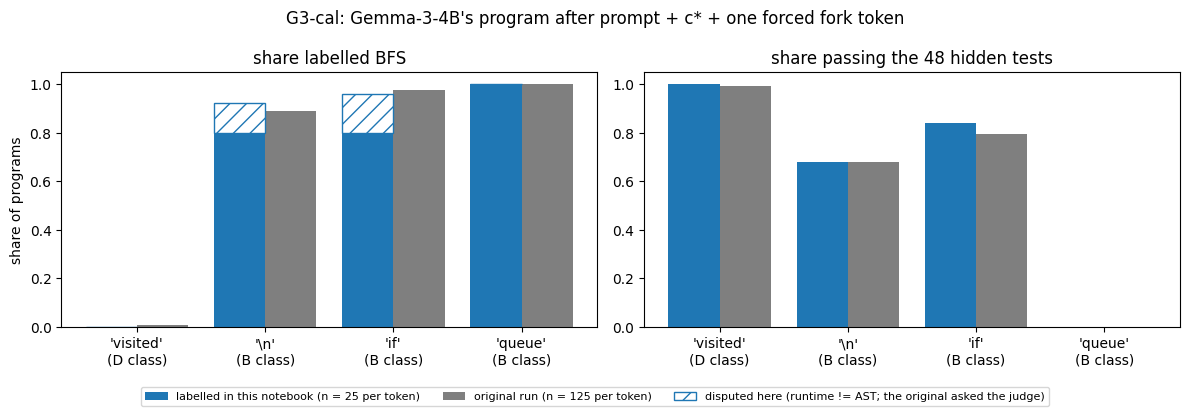

In [24]:
toks = [53227, 107, 584, 15204]
bt = rec["g3_cal"]["by_token"]
grp = {t: cmp[cmp.tok == t] for t in toks}
bfs_now = np.array([grp[t].label_now.str.startswith("bfs").mean() if len(grp[t]) else np.nan for t in toks])
disputed_now = np.array([grp[t].label_now.str.startswith("disputed").mean() if len(grp[t]) else np.nan for t in toks])
pass_now = [grp[t].label_now.str.endswith("pass").mean() if len(grp[t]) else np.nan for t in toks]
n_now = sorted({len(grp[t]) for t in toks})
n_lab = f"{n_now[0]}-{n_now[-1]}" if len(n_now) > 1 else str(n_now[0])
x = np.arange(len(toks))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, now, recd, ttl in ((axes[0], bfs_now, [bt[str(t)]["p_bfs_of_all"] for t in toks], "share labelled BFS"),
                           (axes[1], pass_now, [bt[str(t)]["n_pass"] / bt[str(t)]["n"] for t in toks],
                            "share passing the 48 hidden tests")):
    ax.bar(x - 0.2, now, 0.4, label=f"labelled in this notebook (n = {n_lab} per token)", color="tab:blue")
    ax.bar(x + 0.2, recd, 0.4, label="original run (n = 125 per token)", color="tab:gray")
    ax.set_xticks(x, [f"'{FORK_TOKEN_NAME[t]}'\n({'D' if t in D_IDS else 'B'} class)" for t in toks])
    ax.set_ylim(0, 1.05)
    ax.set_title(ttl)
axes[0].bar(x - 0.2, disputed_now, 0.4, bottom=bfs_now, color="none", edgecolor="tab:blue", hatch="//",
            label="disputed here (runtime != AST; the original asked the judge)")
axes[0].set_ylabel("share of programs")
fig.suptitle("G3-cal: Gemma-3-4B's program after prompt + c* + one forced fork token")
plt.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, fontsize=8)
plt.show()

### Figure 2: the DAS toy (computed here)

Left: principal-angle cosines between the learned R and the planted Q; the pass threshold is 0.9. Right: training
and held-out KL against the no-edit baseline.
* **DAS** recovers the first planted direction almost exactly. The second is recovered only partly (deviation D13),
  so the toy's strict `pass` flag is `False`, as in the original run.
* **SHUF** stays far above DAS on held-out pairs.
* The **plan's optimiser** barely moves.
* **Small n** fits the training pairs and fails on held-out ones.

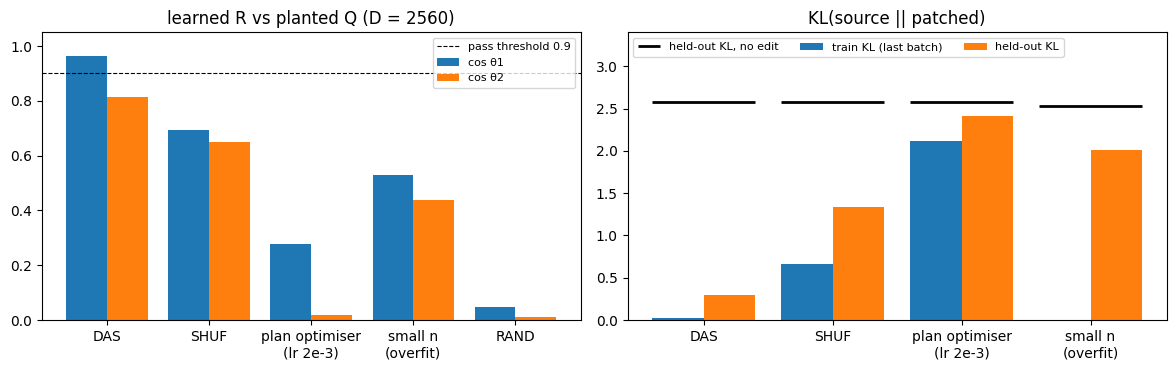

In [25]:
cfg_names = ["das", "shuf", "plan_optimiser_lr2e-3", "small_n_overfit"]
labels_ = ["DAS", "SHUF", "plan optimiser\n(lr 2e-3)", "small n\n(overfit)", "RAND"]
pc = np.array([toy_now[c]["principal_cosines"] for c in cfg_names] + [toy_now["rand_principal_cosines"]])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(labels_))
axes[0].bar(x - 0.2, pc[:, 0], 0.4, label="cos θ1")
axes[0].bar(x + 0.2, pc[:, 1], 0.4, label="cos θ2")
axes[0].axhline(0.9, ls="--", c="k", lw=0.8, label="pass threshold 0.9")
axes[0].set_xticks(x, labels_)
axes[0].set_ylim(0, 1.05)
axes[0].set_title(f"learned R vs planted Q (D = {D_MODEL})")
axes[0].legend(fontsize=8)
x = np.arange(len(cfg_names))
axes[1].bar(x - 0.2, [toy_now[c]["train_kl"] for c in cfg_names], 0.4, label="train KL (last batch)")
axes[1].bar(x + 0.2, [toy_now[c]["heldout_kl"] for c in cfg_names], 0.4, label="held-out KL")
axes[1].hlines([toy_now[c]["heldout_kl_no_edit"] for c in cfg_names], x - 0.4, x + 0.4, colors="k", lw=2,
              label="held-out KL, no edit")
axes[1].set_xticks(x, labels_[:4])
axes[1].set_ylim(0, 3.4)
axes[1].set_title("KL(source || patched)")
axes[1].legend(loc="upper left", fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

### Figure 3: G2, the dose dial at the fork (recorded GPU result)

One edit at layer L\* = 17 at the fork position, N = 50 CRN-paired twin programs per cell. The edit moves the state
by a fraction λ (the dose) toward the BFS (or DFS) class mean, either inside the rank-4 **DAS** subspace or along the
**difference in means (DiM)** direction at the same teacher-forced effect.
* **DAS** adds *correct* BFS programs (11 → 42 at λ = 1) and keeps the pass rate. That beats an explicit "uses BFS"
  prompt.
* **DiM** flips the algorithm too, but it destroys the programs.
* **RAND** (a random rank-4 subspace) does nothing.

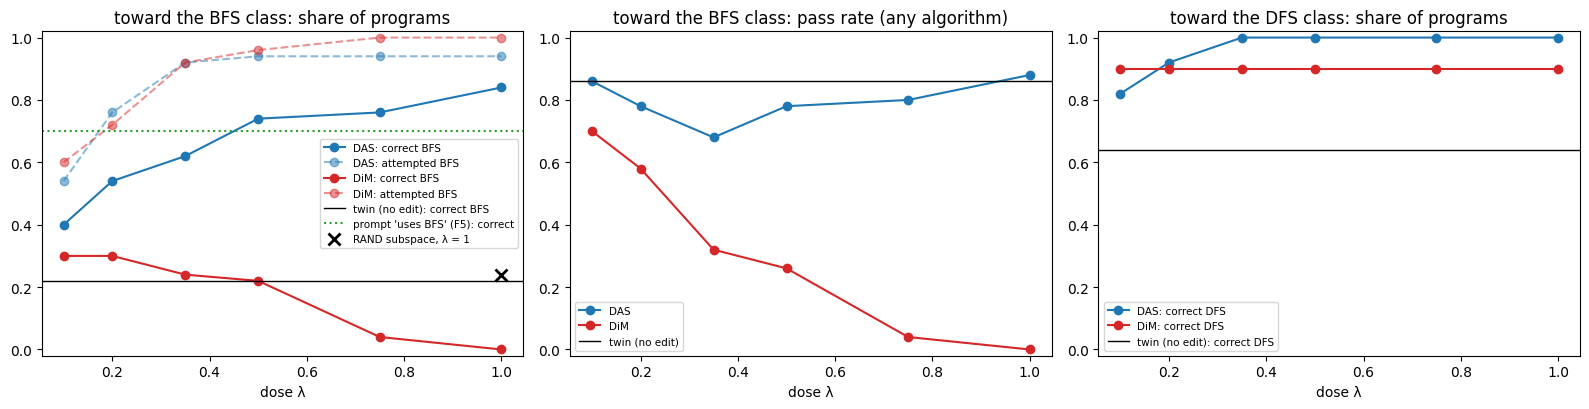

G2-KNOB (committed rule): DAS toward BFS = True | DiM toward BFS = False


In [26]:
cells = rec["g2_dose"]["cells"]
doses = [0.1, 0.2, 0.35, 0.5, 0.75, 1.0]
tw = rec["g2_dose"]["twin"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for meth, col in (("DAS", "tab:blue"), ("DiM", "tab:red")):
    c = [cells[f"{meth}|bfs|{d}"] for d in doses]
    axes[0].plot(doses, [z["correct_share"] for z in c], "o-", c=col, label=f"{meth}: correct BFS")
    axes[0].plot(doses, [z["attempted_share"] for z in c], "o--", c=col, alpha=0.5, label=f"{meth}: attempted BFS")
    axes[1].plot(doses, [z["pass_rate"] for z in c], "o-", c=col, label=meth)
    c = [cells[f"{meth}|dfs|{d}"] for d in doses]
    axes[2].plot(doses, [z["correct_share"] for z in c], "o-", c=col, label=f"{meth}: correct DFS")
for ax, val, lab in ((axes[0], tw["correct_share"], "twin (no edit): correct BFS"), (axes[1], tw["pass_rate"], "twin (no edit)"),
                     (axes[2], rec["g2_dose"]["knob"]["DAS|dfs"]["twin_correct_target"] / tw["n"], "twin (no edit): correct DFS")):
    ax.axhline(val, c="k", lw=1, label=lab)
axes[0].axhline(cells["forced_bfs_F5"]["correct_share"], c="tab:green", ls=":", label="prompt 'uses BFS' (F5): correct")
axes[0].plot([1.0], [cells["RAND|bfs|1.0"]["correct_share"]], "kx", ms=9, mew=2, label="RAND subspace, λ = 1")
axes[0].set_title("toward the BFS class: share of programs")
axes[1].set_title("toward the BFS class: pass rate (any algorithm)")
axes[2].set_title("toward the DFS class: share of programs")
for ax in axes:
    ax.set_xlabel("dose λ")
    ax.set_ylim(-0.02, 1.02)
    ax.legend(fontsize=7.5)
plt.tight_layout()
plt.show()
kn = rec["g2_dose"]["knob"]
print("G2-KNOB (committed rule): DAS toward BFS =", kn["DAS|bfs"]["G2_KNOB"], "| DiM toward BFS =", kn["DiM|bfs"]["G2_KNOB"])

### Figure 4: G3, temperature acts only through the fork (recorded GPU result)

Before any temperature sample was drawn, commit #1 fixed one prediction per cell from teacher-forced logits:
P(c\*) × softmax(z_fork / T) × P(BFS | fork token). Observed shares (N = 50, CRN slots, Wilson 95% CIs) match the
prediction within 0.08 at every T (mean absolute error 0.026). Top-k 10 changes nothing, because the B and D tokens are always in the top 10. At low T the
model has one idea (DFS). Raising T only moves probability mass across the fork it already has, and adds no new
algorithm.

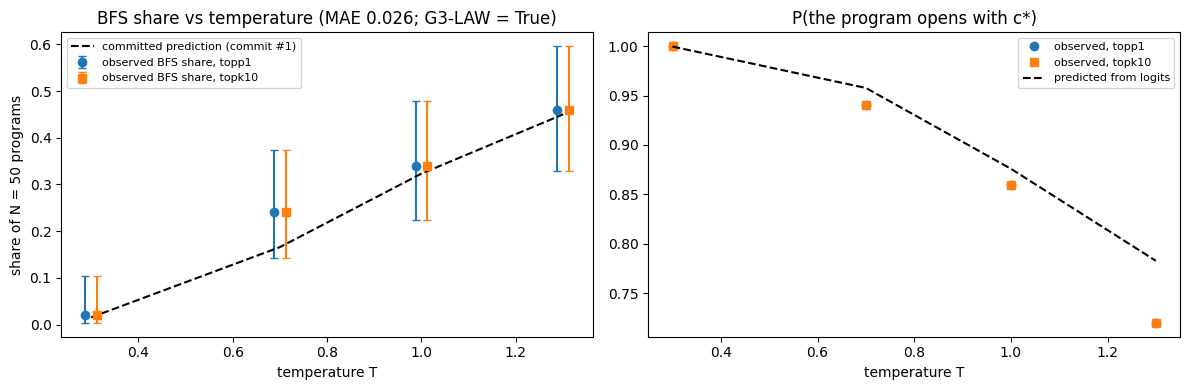

H(label | fork class) pooled = 0.153 bits (G3-CONC = True); T 1.0 -> 0.3 switches 16/50 programs to DFS and 0 back


In [27]:
sw = rec["g3_sweep"]["cells"]
Ts = [0.3, 0.7, 1.0, 1.3]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for sampler, mk, dx, col in (("topp1", "o", -0.012, "tab:blue"), ("topk10", "s", 0.012, "tab:orange")):
    c = [sw[f"T{T}|{sampler}"] for T in Ts]
    obs = np.array([z["attempted_share"] for z in c])
    ci = np.array([z["ci95"] for z in c])
    axes[0].errorbar(np.array(Ts) + dx, obs, yerr=[obs - ci[:, 0], ci[:, 1] - obs], fmt=mk, c=col, capsize=3,
                     label=f"observed BFS share, {sampler}")
    axes[1].plot(Ts, [z["observed_P_cstar"] for z in c], mk, c=col, label=f"observed, {sampler}")
axes[0].plot(Ts, [sw[f"T{T}|topp1"]["pred_primary"] for T in Ts], "k--", label="committed prediction (commit #1)")
axes[1].plot(Ts, [sw[f"T{T}|topp1"]["predicted_P_cstar"] for T in Ts], "k--", label="predicted from logits")
axes[0].set_title(f"BFS share vs temperature (MAE {rec['g3_sweep']['MAE_topp1']:.3f}; G3-LAW = {rec['g3_sweep']['G3_LAW']})")
axes[1].set_title("P(the program opens with c*)")
for ax in axes:
    ax.set_xlabel("temperature T")
    ax.legend(fontsize=8)
axes[0].set_ylabel("share of N = 50 programs")
plt.tight_layout()
plt.show()
print(f"H(label | fork class) pooled = {rec['g3_sweep']['H_label_given_fork_pooled_bits']:.3f} bits "
      f"(G3-CONC = {rec['g3_sweep']['G3_CONC']}); T 1.0 -> 0.3 switches "
      f"{rec['g3_sweep']['mcnemar_T1_vs_T03']['topp1']['T1_bfs_T03_not']}/50 programs to DFS and "
      f"{rec['g3_sweep']['mcnemar_T1_vs_T03']['topp1']['T03_bfs_T1_not']} back")

### Figure 5: geometry of the fork margin, and where the circuit acts (recorded GPU result)

Left: the fork margin m for 160 prompts.
* The 120 **neutral twin variants** (5 "do not use <noun>" templates × 24 nouns) sit in a narrow band below 0, so
  DFS is favoured.
* The 40 **forced prompts** (5 "use BFS/DFS" templates × 4 display names × the two algorithms) sit far out on
  either side.

These are the sources whose states G2's DAS transfers into the twins. The dotted line at m = 0 is where P(B) = P(D).
Right: G1's exact patching effect shared out by position class. The fork position and the condition sentence (where
the prompt's noun enters) carry almost all of it.

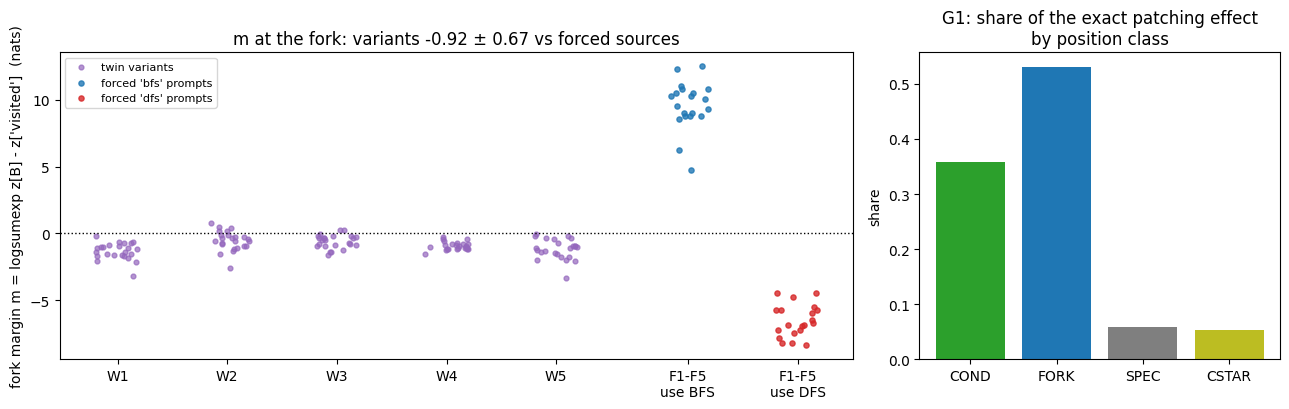

G1 top-10 nodes (path patching): ['mlp|L0|H-1|COND', 'mlp|L6|H-1|COND', 'mlp|L25|H-1|FORK', 'mlp|L21|H-1|FORK', 'mlp|L2|H-1|COND', 'head|L22|H5|FORK', 'mlp|L26|H-1|FORK', 'mlp|L14|H-1|COND', 'mlp|L22|H-1|FORK', 'mlp|L17|H-1|FORK']
node claims (committed rule, vs 50 write-norm-matched random nodes each): {'ablate': 7, 'steer': 8}


In [28]:
yv = rec["yv"]
var = pd.DataFrame(yv["variants"])
src = pd.DataFrame(yv["sources"])
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
for i, w in enumerate(TEMPLATE_IDS):
    y = var[var.template == w].y.values
    ax.scatter(i + rng.uniform(-0.2, 0.2, len(y)), y, s=12, alpha=0.7, label="twin variants" if i == 0 else None, c="tab:purple")
for j, (mode, col) in enumerate((("bfs", "tab:blue"), ("dfs", "tab:red"))):
    y = src[src["mode"] == mode].y.values
    ax.scatter(5.2 + j + rng.uniform(-0.2, 0.2, len(y)), y, s=14, alpha=0.8, c=col, label=f"forced '{mode}' prompts")
ax.axhline(0, c="k", ls=":", lw=1)
ax.set_xticks(list(range(5)) + [5.2, 6.2], TEMPLATE_IDS + ["F1-F5\nuse BFS", "F1-F5\nuse DFS"])
ax.set_ylabel("fork margin m = logsumexp z[B] - z['visited']  (nats)")
ax.set_title(f"m at the fork: variants {yv['y_mean']:.2f} ± {yv['y_sd']:.2f} vs forced sources")
ax.legend(fontsize=8, loc="upper left")
sh = rec["g1_extras"]["exact_effect_share_by_class"]
axes[1].bar(list(sh), list(sh.values()), color=["tab:green", "tab:blue", "tab:gray", "tab:olive"])
axes[1].set_title("G1: share of the exact patching effect\nby position class")
axes[1].set_ylabel("share")
plt.tight_layout()
plt.show()
print("G1 top-10 nodes (path patching):", rec["g1_pathpatch"]["top10"])
print("node claims (committed rule, vs 50 write-norm-matched random nodes each):", rec["g1_validation"]["n_node_claims"])

In [29]:
# Committed decisions and audit, as recorded by the original run
gd = rec["g2_decisions"]
decisions = {
    "ENGINE_CHECK (twin share inside iteration 6's CI)": rec["engine_check"]["pass"],
    "U6 diagnosis": ", ".join(rec["u6"]["diagnosis"]),
    "G3_LAW (|pred - obs| <= 0.10 in every top-p-1 cell)": rec["g3_sweep"]["G3_LAW"],
    "G3_CONC (H(label | fork class) <= 0.3 bits)": rec["g3_sweep"]["G3_CONC"],
    "G2_DAS_REAL (DAS beats RAND/SHUF/RINIT on held-out pairs)": gd["G2_DAS_REAL"],
    "L* / k* / smallest sufficient rank": f"{gd['L_star']} / {gd['k_star']} / {gd['smallest_sufficient_rank']}",
    "G2_KNOB, DAS toward BFS": rec["g2_dose"]["knob"]["DAS|bfs"]["G2_KNOB"],
    "G2_KNOB, DiM toward BFS": rec["g2_dose"]["knob"]["DiM|bfs"]["G2_KNOB"],
    "G1 node claims (ablate / steer, of 10)": f"{rec['g1_validation']['n_node_claims']['ablate']} / {rec['g1_validation']['n_node_claims']['steer']}",
    "novelty audit: correct programs labelled 'other'": f"{rec['novelty_audit']['n_correct_other']} of {rec['novelty_audit']['n_correct_programs_all_arms']}",
    "hash chain verified, each commit before its samples": f"{rec['verify_chain']['all_ok']} "
                                                            f"({len(rec['verify_chain']['entries'])} commits)",
    "OpenRouter spend (USD)": rec["costs"]["total_usd"],
    "GPU-stage time (h)": round(sum(v for k, v in rec["timing"]["seconds_by_stage"].items() if k in GPU_STAGES and k != "s0") / 3600, 2),
}
display(pd.DataFrame({"recorded": [str(v) for v in decisions.values()]}, index=list(decisions)))

,recorded
ENGINE_CHECK (twin share inside iteration 6's CI),False
U6 diagnosis,batching ((a) differs from (b))
G3_LAW (|pred - obs| <= 0.10 in every top-p-1 cell),True
G3_CONC (H(label | fork class) <= 0.3 bits),True
G2_DAS_REAL (DAS beats RAND/SHUF/RINIT on held-out pairs),True
L* / k* / smallest sufficient rank,17 / 4 / 1
"G2_KNOB, DAS toward BFS",True
"G2_KNOB, DiM toward BFS",False
"G1 node claims (ablate / steer, of 10)",7 / 8
novelty audit: correct programs labelled 'other',0 of 2325


## Takeaways

* **This notebook reproduces the CPU half of the pipeline from scratch.**
  * The vendored files match their sha256 manifest.
  * The frozen labeller gets every reference program right, and the hidden tests reject every mutant.
  * The CRN streams are deterministic.
  * The DAS toy reproduces the recorded numbers to the digit (same seeds, same code).
  * On the Gemma programs, the labeller gives the recorded label wherever its runtime and AST views agree. The few
    rows the original sent to the LLM judge come out `disputed` here.
* **The fork is a switch.** One token at response index 32 nearly fixes the algorithm: ` visited` leads to DFS; a
  blank line, `if` or `queue` lead to BFS.
* **Temperature is not a creativity knob here (G3).** It moves probability mass across this single fork, as
  predicted from the logits before any temperature sample was drawn. Across 2,325 correct programs, no new algorithm appeared.
* **A controlled DAS subspace at layer 17 is a working dose dial (G2).** It raises correct BFS programs from 11 to
  42 of 50 without breaking them. A difference-in-means push of the same size flips the algorithm but breaks the
  code.
* **Scope.** One model, one task, one natural fork: a case study, not a general circuit claim. To run the GPU stages,
  clone the repository and run `python method.py --stage <name>` in the artifact folder on a CUDA GPU with access to
  `google/gemma-3-4b-it`.